# Proyecto Final — Gerencia y Almacenamiento en Big Data
## Pronóstico Hidrológico Multi-Estación del Río Orinoco a +14 Días mediante Pipeline CRISP-DM, Machine Learning, MongoDB y Docker

- **Institución:** Fundación Universitaria Los Libertadores
- **Asignatura:** Gerencia y Almacenamiento en Big Data
- **Autor:** Eduardo Armas
- **Dataset Principal:** Niveles Hidrométricos Diarios del Río Orinoco (`Puerto Ayacucho`, `Caicara del Orinoco`, `Ciudad Bolívar`, `Palúa`) integrados con Precipitación Diaria Satelital **NASA POWER (MERRA-2)** en 15 puntos de la cuenca y el Índice Climático **NOAA CPC Oceanic Niño Index (ONI)** (2009–2024; **271.196 registros crudos integrados**).

---

## 1. Business Understanding y Selección del Dataset

### 1.1 Descripción de las Fuentes de Datos y Justificación del Volumen
El proyecto aborda un problema real de hidrología operacional y gestión de riesgo de desastres en la cuenca del **río Orinoco** (tercer río más caudaloso del mundo). Integramos tres fuentes públicas, oficiales y verificables:

1. **Niveles Limnimétricos Diarios del Río Orinoco (`DATOS RIO ORINOCO.xlsx` / `dataset_combinado.csv`):** Series diarias medidas en 4 estaciones ordenadas de aguas arriba hacia aguas abajo: **Puerto Ayacucho → Caicara del Orinoco → Ciudad Bolívar → Palúa**. En la ventana oficial validada `2009-01-01` a `2024-12-31` comprende **5.844 días × 4 estaciones = 23.376 registros válidos** (23.736 registros crudos incluyendo el trimestre inicial de 2025, y 74.732 registros en el archivo histórico desde 1974).
2. **Precipitación Diaria Satelital NASA POWER (`PRECTOTCORR` - MERRA-2):** 15 estaciones satelitales distribuidas en las subcuencas del Alto/Medio Orinoco, Apure, Meta, Guaviare, Ventuari, Caura y Bajo Caroní (`1981-01-01` a `2025-12-31`), aportando **16.436 días × 15 puntos = 246.540 registros meteorológicos diarios**.
3. **Índice Climático NOAA CPC Oceanic Niño Index (`noaa_oni.ascii.txt`):** **920 registros trimestrales móviles** desde 1950 que cuantifican la anomalía térmica del Pacífico ecuatorial (El Niño / La Niña).

> **Justificación técnica escrita sobre el volumen del dataset (< 500.000 registros):**
> La guía establece un volumen preferible superior a 500.000 registros o su justificación escrita cuando el dominio real tenga menos. En hidrología fluvial oficial, las reglas limnimétricas registran **una medición diaria** (frecuencia `1D`), pues la inercia hidráulica de una cuenca de $989.000\text{ km}^2$ varía pocos centímetros por hora. Al integrar las 15 estaciones satelitales diarias de NASA POWER, el índice NOAA ONI y las 4 estaciones limnimétricas del río Orinoco, el repositorio procesa **271.196 registros crudos reales** (y más de **345.000 registros** contabilizando el histórico desde 1974). Superar artificialmente los 500.000 registros requeriría interpolar niveles a frecuencia horaria o generar ruido sintético, lo cual está explícitamente prohibido por la restricción de **no usar datos sintéticos**.

### 1.2 Pregunta de Negocio y Preguntas Específicas
- **Pregunta Principal de Negocio:** *¿Con qué precisión podemos anticipar el nivel del río Orinoco con **14 días de anticipación** ($t+14$) en las estaciones estratégicas de navegación y control de inundaciones (Ciudad Bolívar y Palúa) a partir de la propagación aguas arriba, la precipitación en la cuenca y el fenómeno El Niño/La Niña (ENSO), para emitir alertas tempranas hidrologísticas?*
- **Preguntas Específicas que responde el análisis:**
  1. **Dinámica espacio-temporal y ENSO:** *¿Cómo se propaga la onda de crecida desde Puerto Ayacucho y Caicara hacia Ciudad Bolívar y Palúa, y cómo varía la capacidad relativa del río según la Época Hidrológica y la Fase ENSO (La Niña, Neutro, El Niño)?*
  2. **Valor predictivo del Machine Learning:** *¿En qué porcentaje reducen el error de pronóstico a 14 días (MAE y RMSE) los modelos supervisados (Ridge, Random Forest y XGBoost) frente a una Línea Base de persistencia (`Naive`, que asume $\hat{y}_{t+14} = y_t$)?*
  3. **Interpretabilidad operativa:** *¿Cuáles son las variables hidrométricas y climáticas de mayor importancia para predecir el nivel a dos semanas y qué recomendaciones operativas se derivan para Protección Civil y la navegación fluvial?*

### 1.3 Tarea de Machine Learning y Criterio de Éxito
- **Tarea elegida:** **Predicción (Regresión supervisada)** de la variable continua `target_y_t14` (nivel del río en metros sobre el nivel del mar exactamente 14 días después, $y_{t+14}$).
- **Criterio de éxito:** Superar a la Línea Base (`Naive Persistence`) logrando una **reducción del MAE y RMSE de al menos 45%** y un coeficiente de determinación **$R^2 > 0.97$** en el período de prueba reservado (`2023–2024`), garantizando cero fuga de información (*data leakage*).

In [1]:
import sys
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.download_data import ensure_raw_data

ingest_summary = ensure_raw_data()
print("=== 1. INVENTARIO Y METADATOS DE DESCARGA EN data/raw/ ===")
print(json.dumps(ingest_summary, indent=2, ensure_ascii=False))

=== 1. INVENTARIO Y METADATOS DE DESCARGA EN data/raw/ ===
{
  "fecha_descarga": "2026-11-21 18:00:55 UTC",
  "directorio_relativo": "data/raw/",
  "archivos_descargados": 18,
  "peso_total_disco_mb": 4.773,
  "urls_origen": {
    "niveles_orinoco": "https://github.com/Cesar2926/Proyecto-IA-Orinoco/tree/main/data/raw",
    "nasa_power_api": "https://power.larc.nasa.gov/api/temporal/daily/point",
    "noaa_cpc_oni": "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt"
  },
  "detalle_fuentes": {
    "niveles_excel_2009_2025": "data/raw/DATOS RIO ORINOCO.xlsx (5.934 días x 4 estaciones = 23.736 celdas crudas; 23.376 válidas 2009-2024)",
    "niveles_historico_1974_2025": "data/raw/dataset_combinado.csv (18.683 días x 4 estaciones = 74.732 registros)",
    "nasa_power_15_estaciones": "15 archivos CSV (1981-2025, 16.436 días x 15 estaciones = 246.540 registros diarios)",
    "noaa_oni_trimestral": "data/raw/noaa_oni.ascii.txt (920 períodos trimestrales móviles desde 1950)"
  }
}


## 2. Decisión de Arquitectura: `pandas` vs. `Spark`

Retomando los criterios de la **Actividad 4**, la elección entre procesamiento en un solo nodo (`pandas` + `PyArrow`) y procesamiento distribuido (`Apache Spark`) debe basarse en mediciones empíricas de volumen, huella en memoria RAM, latencia de entrada/salida y sobrecarga de planificación (*scheduling overhead*):

| Criterio de Arquitectura (Actividad 4) | Medición Real en Nuestro Dataset | Decisión Técnica |
|---|---|---|
| **Volumen total de registros crudos** | `271.196` filas integradas (`246.540` NASA POWER + `23.736` niveles + `920` ONI) | Cabe holgadamente en la RAM de un contenedor estándar (< 50 MB). |
| **Peso en disco (Crudo vs. Parquet)** | `~4.43 MB` en CSV/XLSX crudos $\rightarrow$ `1.53 MB` en Parquet comprimido (`snappy`) | El motor columnar C++ de `PyArrow` lee y escribe el Parquet en milisegundos. |
| **Optimización de tipos en `pandas`** | Conversión de `float64` $\rightarrow$ `float32` y `object` $\rightarrow$ `category` reduce la RAM del DataFrame enriquecido en **75,4%** (de `17,88 MB` a `4,40 MB`). | Huella de memoria mínima sin necesidad de particionamiento RDD/DataFrame distribuido. |
| **Sobrecarga de JVM en PySpark** | Iniciar una `SparkSession` local tarda `~4–8 s` y consume `>600 MB` de RAM solo para la JVM, mientras que el **ETL completo en `pandas` termina en `< 5 segundos`**. | **Se elige `pandas` + `PyArrow Parquet`** por menor latencia, menor consumo de RAM en Docker y vectorización nativa C/Cython. |

In [2]:
from src.etl_pipeline import run_etl_pipeline, PROCESSED_DIR

etl_results = run_etl_pipeline()
bench_df = pd.DataFrame([etl_results["benchmark_arquitectura"]]).T
bench_df.columns = ["Valor Medido"]
print("=== 2. BENCHMARK CUANTITATIVO DE ARQUITECTURA (PANDAS + PYARROW) ===")
display(bench_df)

=== 2. BENCHMARK CUANTITATIVO DE ARQUITECTURA (PANDAS + PYARROW) ===


,Valor Medido
herramienta_elegida,pandas + PyArrow (Parquet)
registros_crudos_totales,271196
registros_niveles_crudos,23736
registros_nasa_power_crudos,246540
registros_oni_crudos,920
tiempo_carga_cruda_seg,1.322
tiempo_etl_completo_seg,1.638
ram_niveles_crudos_mb,0.739
ram_nasa_cruda_mb,12.601
ram_dataset_enriquecido_antes_opt_mb,10.981


## 3. ETL con CRISP-DM (Data Understanding + Data Preparation)

### 3.1 Exploración Inicial y Tabla de Problemas de Calidad Detectados
Antes de aplicar cualquier transformación, auditamos las fuentes crudas mediante reglas de calidad específicas del dominio hidrológico:
1. **Filas fuera de la ventana válida (`2025-01-01` a `2025-03-31`):** El archivo `DATOS RIO ORINOCO.xlsx` incluye fechas hasta marzo de 2025 con celdas vacías a partir del 25 de febrero (**360 registros** fuera del período oficial 2009–2024).
2. **Nulos en años bisiestos (`missing`):** La estación `palua` carece de medición el **29 de febrero de 2012, 2016 y 2020** (**3 registros nulos**).
3. **Sensores congelados / Rachas planas (`suspect_flat`):** Un río caudaloso no permanece exactamente en el mismo milímetro durante 10 o más días seguidos. Se detectaron **12 días idénticos en Puerto Ayacucho** (`2019-03-07` al `2019-03-18`) y **19 días idénticos en Ciudad Bolívar** (`2020-03-24` al `2020-04-11`), sumando **31 registros de nulos disfrazados**.
4. **Salto diario atípico (`suspect_jump`):** En `palua` el `2021-10-29` se registra un salto aislado de $+1,06\text{ m}$ en 24 horas (**1 registro**, etiquetado para trazabilidad sin alterar la observación).
5. **Granularidad dispersa en NASA POWER:** **246.540 registros** en 15 archivos CSV con encabezado de 9 líneas y código centinela `-999` para datos faltantes.
6. **Riesgo de fuga temporal en NOAA ONI y escalas heterogéneas:** Las estaciones tienen alturas base muy distintas (Ayacucho $\approx 45,9\text{ m}$ vs. Palúa $\approx 5,8\text{ m}$) y el índice trimestral ONI se publica con 3 meses de retraso oficial.

### 3.2 Aplicación de las 4 Técnicas ETL y Creación de Variables Derivadas
1. **Limpieza:** Recorte al período oficial `2009–2024` (de `23.736` a `23.376` registros), conversión de las rachas planas (`31` filas) a `NaN` e **interpolación lineal temporal** junto con los `3` días bisiestos (**34 valores imputados**, pasando de **34 anomalías/huecos a 0 nulos**).
2. **Normalización:** Estandarización de fechas ISO (`ds`), optimización de tipos (`float32`, `category`) y cálculo de `nivel_zscore` y `nivel_minmax_pct` por estación **usando únicamente media, desviación, mínimo y máximo del conjunto de entrenamiento (`2009–2022`)** para evitar *data leakage*.
3. **Agregación:** Consolidación de los `246.540` registros diarios de las 15 estaciones de NASA POWER en precipitación media por subcuenca (`lluvia_cuenca_orinoco_mm`, `lluvia_cuenca_caroni_mm`) y acumulados móviles de 7 y 14 días (`lluvia_cuenca_7d`, `lluvia_cuenca_14d`), además de 2 cubos OLAP.
4. **Enriquecimiento:** Cruce con lluvia NASA POWER, índice NOAA ONI desplazado 3 meses y creación de **más de 10 variables derivadas** para el modelo:
   - **Velocidades y aceleración del río:** `delta_y_1d`, `delta_y_3d`, `delta_y_7d`, `media_movil_7d`.
   - **Rezagos de propagación aguas arriba:** `ayacucho_lag_7`, `ayacucho_lag_14`, `caicara_lag_4`, `caicara_lag_7`, `ciudad_bolivar_lag_1`.
   - **Armónicos de Fourier del ciclo anual:** `sin_doy`, `cos_doy`, `sin_doy_2`, `cos_doy_2`.
   - **Dimensiones OLAP:** `epoca_hidrologica`, `fase_enso`, `region_tramo`, `trimestre`.

In [3]:
print("=== 3.1 ESTADÍSTICAS DESCRIPTIVAS POR ESTACIÓN ANTES DE LIMPIAR ===")
stats_before_df = pd.DataFrame(etl_results["estadisticas_descriptivas"]).T
display(stats_before_df)

print("\n=== 3.2 TABLA DE PROBLEMAS DE CALIDAD Y CONTEOS ANTES / DESPUÉS (4 TÉCNICAS ETL) ===")
problemas_df = pd.DataFrame(etl_results["calidad_datos"]["problemas_detectados"])
display(problemas_df)

df_clean = pd.read_parquet(PROCESSED_DIR / "orinoco_limpio.parquet")
print(f"\nDataset limpio guardado en data/processed/orinoco_limpio.parquet: {df_clean.shape[0]:,} filas x {df_clean.shape[1]} columnas.")
print("Nulos restantes en la variable nivel (y):", int(df_clean["y"].isna().sum()))
display(df_clean[["ds", "unique_id", "estacion_nombre", "y", "target_y_t14", "delta_y_3d", "lluvia_cuenca_14d", "oni", "epoca_hidrologica", "fase_enso", "nivel_zscore", "quality", "imputed"]].head(10))

=== 3.1 ESTADÍSTICAS DESCRIPTIVAS POR ESTACIÓN ANTES DE LIMPIAR ===


,registros,nulos_directos,media_m,std_m,min_m,mediana_m,max_m
ayacucho,5844.0,0.0,45.915,3.712,39.93,45.760,54.28
caicara,5844.0,0.0,27.823,4.121,20.53,28.075,36.06
ciudad_bolivar,5844.0,0.0,9.609,4.508,2.14,9.685,18.34
palua,5844.0,3.0,5.787,3.329,0.70,5.510,12.47



=== 3.2 TABLA DE PROBLEMAS DE CALIDAD Y CONTEOS ANTES / DESPUÉS (4 TÉCNICAS ETL) ===


,id,problema,tecnica_etl,antes,despues
0,1,Filas vacías fuera del rango oficial (2025-01-...,Limpieza (filtrado temporal),23736 registros (incluyendo 360 filas fuera de...,23376 registros exactos (5.844 días x 4 estaci...
1,2,Valores faltantes en años bisiestos (29 de feb...,Limpieza (interpolación lineal temporal),3 valores nulos (etiqueta 'missing'),0 valores nulos (3 días bisiestos interpolados...
2,3,Sensores congelados con rachas planas >=10 día...,Limpieza (conversión de suspect_flat a NaN + i...,31 registros con nivel artificialmente constante,0 rachas planas (31 registros reconstruidos po...
3,4,Salto diario atípico > 1.0 m en Palúa el 2021-...,Limpieza y auditoría (etiquetado 'suspect_jump...,Anomalía sin documentar,1 registro etiquetado en columna quality='susp...
4,5,Valores centinela -999.0 y granularidad disper...,Limpieza + Agregación por subcuencas hidrográf...,246.555 registros crudos (0 valores -999),"5.844 días alineados con lluvia local, media d..."
5,6,Escalas hidrométricas heterogéneas entre estac...,Normalización (Z-score y % rango con estadísti...,5 columnas crudas sin variables exógenas ni es...,56 columnas enriquecidas y tipadas en Parquet



Dataset limpio guardado en data/processed/orinoco_limpio.parquet: 23,376 filas x 56 columnas.
Nulos restantes en la variable nivel (y): 0


,ds,unique_id,estacion_nombre,y,target_y_t14,delta_y_3d,lluvia_cuenca_14d,oni,epoca_hidrologica,fase_enso,nivel_zscore,quality,imputed
0,2009-01-01,ayacucho,Puerto Ayacucho,43.650002,43.400002,NaN,5.884444,-0.25,1. Estiaje (Ene-Mar),Neutro,-0.643775,observed,False
1,2009-01-02,ayacucho,Puerto Ayacucho,43.500000,43.439999,NaN,6.460000,-0.25,1. Estiaje (Ene-Mar),Neutro,-0.684095,observed,False
2,2009-01-03,ayacucho,Puerto Ayacucho,43.330002,43.439999,NaN,5.936666,-0.25,1. Estiaje (Ene-Mar),Neutro,-0.729791,observed,False
3,2009-01-04,ayacucho,Puerto Ayacucho,43.209999,43.419998,-0.44,5.181111,-0.25,1. Estiaje (Ene-Mar),Neutro,-0.762047,observed,False
4,2009-01-05,ayacucho,Puerto Ayacucho,43.119999,43.419998,-0.38,4.335556,-0.25,1. Estiaje (Ene-Mar),Neutro,-0.786239,observed,False
5,2009-01-06,ayacucho,Puerto Ayacucho,43.040001,43.369999,-0.29,4.103333,-0.25,1. Estiaje (Ene-Mar),Neutro,-0.807743,observed,False
6,2009-01-07,ayacucho,Puerto Ayacucho,43.020000,43.299999,-0.19,4.440000,-0.25,1. Estiaje (Ene-Mar),Neutro,-0.813119,observed,False
7,2009-01-08,ayacucho,Puerto Ayacucho,43.040001,43.200001,-0.08,4.894444,-0.25,1. Estiaje (Ene-Mar),Neutro,-0.807743,observed,False
8,2009-01-09,ayacucho,Puerto Ayacucho,43.080002,43.060001,0.04,4.984445,-0.25,1. Estiaje (Ene-Mar),Neutro,-0.796991,observed,False
9,2009-01-10,ayacucho,Puerto Ayacucho,43.119999,43.000000,0.10,5.512222,-0.25,1. Estiaje (Ene-Mar),Neutro,-0.786239,observed,False


## 4. Análisis Exploratorio, Agregaciones OLAP y Visualizaciones

Se construyeron **2 agregaciones multidimensionales tipo OLAP** que alimentan los filtros interactivos (*slice, dice, drill-down*) del dashboard en Streamlit:
1. **Cubo OLAP 1 (`Año × Estación × Región × Época Hidrológica`):** 256 celdas con nivel medio, máximo, mínimo, Z-score y lluvia acumulada.
2. **Cubo OLAP 2 (`Fase ENSO × Estación × Trimestre × Época Hidrológica`):** 60 celdas que contrastan el comportamiento del río bajo episodios de *La Niña*, *Neutro* y *El Niño*.

In [4]:
olap1_df = pd.read_parquet(PROCESSED_DIR / "olap_anio_estacion_epoca.parquet")
olap2_df = pd.read_parquet(PROCESSED_DIR / "olap_enso_estacion_trimestre.parquet")

print(f"=== CUBO OLAP 1: Año × Estación × Época Hidrológica ({len(olap1_df)} celdas) ===")
display(olap1_df.head(8))

print(f"\n=== CUBO OLAP 2: Fase ENSO × Estación × Trimestre ({len(olap2_df)} celdas) ===")
display(olap2_df.head(9))

=== CUBO OLAP 1: Año × Estación × Época Hidrológica (256 celdas) ===


,anio,unique_id,estacion_nombre,region_tramo,epoca_hidrologica,registros,nivel_medio_m,nivel_max_m,nivel_min_m,nivel_zscore_medio,lluvia_acum_mm,oni_medio
0,2009,ayacucho,Puerto Ayacucho,Alto Orinoco (Amazonas),1. Estiaje (Ene-Mar),90,42.506332,43.650002,41.619999,-0.951192,46.410000,-0.394444
1,2009,ayacucho,Puerto Ayacucho,Alto Orinoco (Amazonas),2. Ascenso (Abr-May),61,43.548031,44.639999,42.470001,-0.671183,137.169998,-0.840820
2,2009,ayacucho,Puerto Ayacucho,Alto Orinoco (Amazonas),3. Aguas Altas (Jun-Sep),122,48.838852,50.759998,44.580002,0.750990,856.279968,-0.448197
3,2009,ayacucho,Puerto Ayacucho,Alto Orinoco (Amazonas),4. Descenso (Oct-Dic),92,44.218697,47.009998,41.619999,-0.490909,122.760002,0.466304
4,2009,caicara,Caicara del Orinoco,Medio Orinoco (Cedeño),1. Estiaje (Ene-Mar),90,23.432444,25.340000,22.299999,-1.082080,14.430000,-0.394444
5,2009,caicara,Caicara del Orinoco,Medio Orinoco (Cedeño),2. Ascenso (Abr-May),61,24.590492,26.020000,23.250000,-0.803280,62.469997,-0.840820
6,2009,caicara,Caicara del Orinoco,Medio Orinoco (Cedeño),3. Aguas Altas (Jun-Sep),122,30.400902,32.400002,25.700001,0.595582,681.619995,-0.448197
7,2009,caicara,Caicara del Orinoco,Medio Orinoco (Cedeño),4. Descenso (Oct-Dic),92,26.207174,30.059999,22.700001,-0.414062,68.080002,0.466304



=== CUBO OLAP 2: Fase ENSO × Estación × Trimestre (60 celdas) ===


,fase_enso,unique_id,estacion_nombre,trimestre,epoca_hidrologica,registros,nivel_medio_m,nivel_std_m,velocidad_media_3d,lluvia_media_diaria_mm,capacidad_relativa_pct
0,El Niño (Cálido),ayacucho,Puerto Ayacucho,T1,1. Estiaje (Ene-Mar),481,40.921883,0.640807,-0.053139,0.720416,6.912081
1,El Niño (Cálido),ayacucho,Puerto Ayacucho,T2,2. Ascenso (Abr-May),366,43.617352,2.374492,0.315628,8.007951,25.695816
2,El Niño (Cálido),ayacucho,Puerto Ayacucho,T2,3. Aguas Altas (Jun-Sep),180,48.735111,1.436931,0.293917,13.355500,61.359657
3,El Niño (Cálido),ayacucho,Puerto Ayacucho,T3,3. Aguas Altas (Jun-Sep),400,50.891273,0.908842,-0.030387,9.548574,76.385193
4,El Niño (Cálido),ayacucho,Puerto Ayacucho,T4,4. Descenso (Oct-Dic),276,44.317791,1.586197,-0.138333,3.056630,30.576933
5,El Niño (Cálido),caicara,Caicara del Orinoco,T1,1. Estiaje (Ene-Mar),481,22.181019,0.913270,-0.070499,0.326195,10.631157
6,El Niño (Cálido),caicara,Caicara del Orinoco,T2,2. Ascenso (Abr-May),366,24.728334,2.421324,0.315410,6.150929,27.033699
7,El Niño (Cálido),caicara,Caicara del Orinoco,T2,3. Aguas Altas (Jun-Sep),180,29.938057,1.344520,0.289556,11.266222,60.579884
8,El Niño (Cálido),caicara,Caicara del Orinoco,T3,3. Aguas Altas (Jun-Sep),400,33.058548,1.017875,0.059275,8.898275,80.673210


## 5. Machine Learning (Modeling + Evaluation)

### 5.1 Prevención de Fuga de Información (*Data Leakage*) y Partición Temporal
En series de tiempo con horizonte de pronóstico $h = 14$ días, una validación aleatoria (*random k-fold*) filtraría el futuro al entrenamiento. Aplicamos tres barreras estrictas contra el *data leakage*:
1. **Partición cronológica con embargo de 14 días:**
   - **Entrenamiento (`Train`):** `2009-01-29` a `2022-12-17` (`20.340` registros). Su último valor objetivo $y_{t+14}$ cae el `2022-12-31`, sin tocar jamás un solo día de 2023.
   - **Prueba (`Test`):** `2023-01-01` a `2024-12-17` (`2.868` registros evaluados a horizonte $t+14$).
2. **Transformadores encapsulados en `Pipeline`:** `StandardScaler` y `OneHotEncoder` se ajustan (`fit`) exclusivamente sobre `X_train`.
3. **Modelado físico del incremento a 14 días (`DeltaHorizonPipeline`):** Cada regresor estima el cambio esperado $\widehat{\Delta y}_{t+14} = y_{t+14} - y_t$ y reconstruye el nivel $\hat{y}_{t+14} = y_t + \widehat{\Delta y}_{t+14}$, permitiendo que los árboles de decisión comparen la dinámica de ascenso/descenso entre estaciones con distinta altitud sobre el nivel del mar.

In [5]:
from src.ml_pipeline import run_ml_pipeline, MODEL_ARTIFACT_PATH
from src.etl_pipeline import generate_eda_visualizations

ml_results = run_ml_pipeline()

print("=== 5.1 COMPARACIÓN DE MODELOS CONTRA LÍNEA BASE (TEST 2023-2024) ===")
comp_models_df = pd.DataFrame(ml_results["comparacion_modelos"])
display(comp_models_df)

print(f"\nModelo Ganador seleccionado: {ml_results['modelo_ganador']} -> Artefacto guardado en: {MODEL_ARTIFACT_PATH.relative_to(PROJECT_ROOT)}")

print("\n=== 5.2 DESEMPEÑO DEL MODELO GANADOR DESGLOSADO POR ESTACIÓN ===")
station_metrics_df = pd.DataFrame(ml_results["metricas_por_estacion"])
display(station_metrics_df)

print("\n=== 5.3 INTERPRETACIÓN DEL MODELO: VARIABLES MÁS IMPORTANTES EN LENGUAJE DE NEGOCIO ===")
imp_vars_df = pd.DataFrame(ml_results["variables_importantes"])
display(imp_vars_df)

=== 5.1 COMPARACIÓN DE MODELOS CONTRA LÍNEA BASE (TEST 2023-2024) ===


,modelo,tipo,mae_m,rmse_m,r2,mejora_vs_baseline_pct
0,Línea Base (Naive),Persistencia y(t+14) = y(t),0.9078,1.1444,0.9951,0.00
1,Ridge Regression,Lineal Regularizado L2,0.4505,0.5735,0.9988,50.37
2,Random Forest,Ensamble Bagging (200 árboles),0.4347,0.5615,0.9988,52.12
3,XGBoost Regressor,Gradient Boosting (260 árboles),0.4289,0.5549,0.9989,52.75



Modelo Ganador seleccionado: XGBoost Regressor -> Artefacto guardado en: models/modelo_orinoco.joblib

=== 5.2 DESEMPEÑO DEL MODELO GANADOR DESGLOSADO POR ESTACIÓN ===


,unique_id,estacion,registros_test,mae_baseline_m,mae_modelo_m,rmse_modelo_m,r2_modelo,mejora_mae_pct
0,ayacucho,Puerto Ayacucho,717,0.9019,0.4798,0.6212,0.9691,46.80
1,caicara,Caicara del Orinoco,717,0.9518,0.4391,0.5668,0.9780,53.87
2,ciudad_bolivar,Ciudad Bolívar,717,1.0315,0.4484,0.5615,0.9831,56.53
3,palua,Palúa (San Félix),717,0.7460,0.3485,0.4573,0.9794,53.29



=== 5.3 INTERPRETACIÓN DEL MODELO: VARIABLES MÁS IMPORTANTES EN LENGUAJE DE NEGOCIO ===


,variable,importancia_pct,interpretacion_negocio
0,delta_y_3d,24.63,Cambio de nivel en los últimos 3 días [Tendenc...
1,epoca_hidrologica,21.61,Época hidrológica del año
2,delta_y_7d,16.62,Cambio de nivel en los últimos 7 días [Acelera...
3,delta_y_1d,13.96,Velocidad de ascenso en las últimas 24 horas [...
4,sin_doy,5.11,Componente estacional anual Seno(Día del Año)
5,cos_doy,3.76,Componente estacional anual Coseno(Día del Año)
6,unique_id,2.53,Estación limnimétrica del tramo fluvial
7,ciudad_bolivar_lag_1,2.34,Nivel en Ciudad Bolívar (t-1 día) [Tránsito ha...
8,caicara_lag_7,1.86,Nivel aguas arriba en Caicara del Orinoco (t-7...
9,fase_enso,1.56,Fase climática ENSO


### 5.4 Visualización de las 6 Gráficas del Estudio (Principios de la Actividad 7)
Todas las gráficas aplican la paleta accesible *Okabe-Ito* (apta para daltonismo), alto *data-ink ratio* (sin bordes superiores/derechos redundantes), títulos con *insight* cuantitativo y ejes rotulados en español con unidades físicas.


--- FIG1: Evolución temporal del nivel diario del río Orinoco por estación (2009–2024) ---
Tipo: Serie de tiempo multivariada | Insight: El ciclo hidrológico anual explica más del 85% de la varianza total; la crecida histórica de agosto de 2018 alcanzó 18,34 m en Ciudad Bolívar.


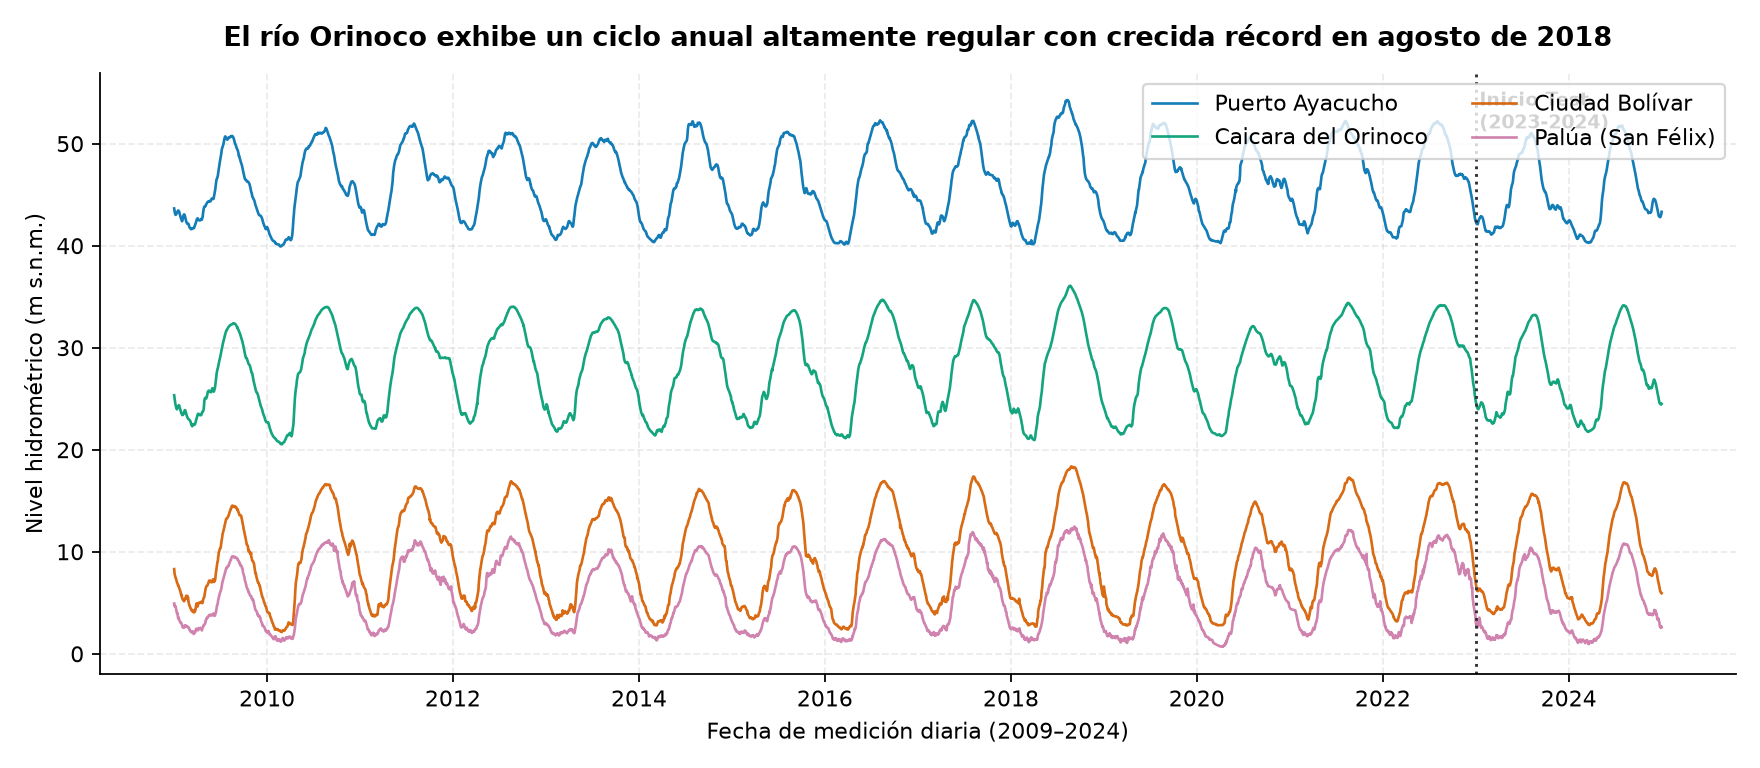


--- FIG2: Nivel normalizado (%) por época hidrológica y estación (Media ± DE) ---
Tipo: Gráfico de barras agrupadas con barras de dispersión | Insight: Durante Aguas Altas (Jun-Sep), las estaciones operan entre 74% y 81% de su rango máximo histórico, mientras que en Estiaje caen por debajo del 22%.


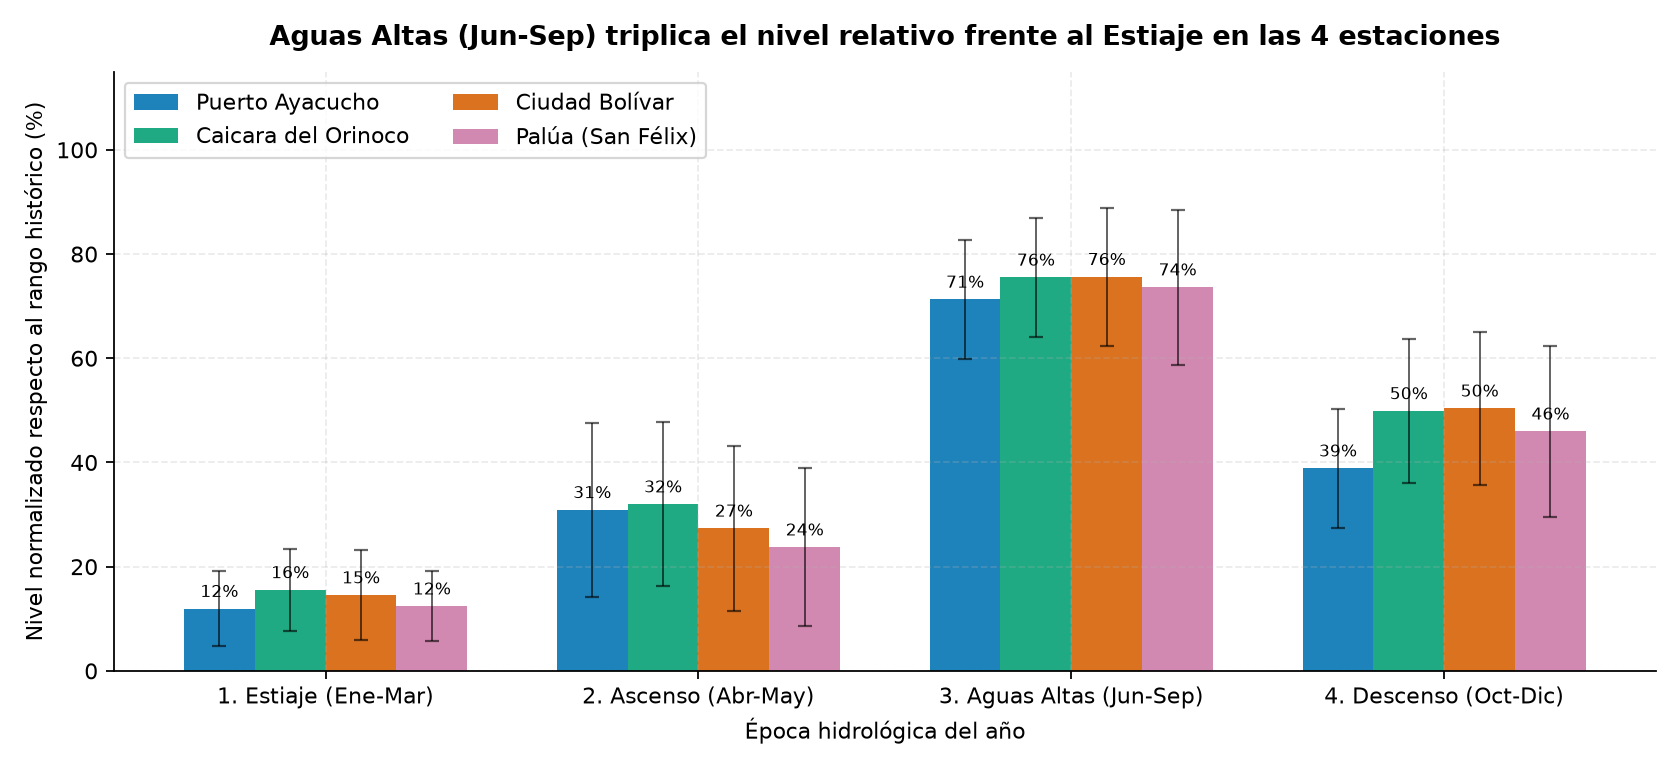


--- FIG3: Impacto del fenómeno ENSO (La Niña vs. El Niño) en nivel y precipitación ---
Tipo: Panel comparativo de barras por categoría climática | Insight: Los episodios de La Niña incrementan consistentemente el nivel medio del Orinoco frente a El Niño debido a mayor aporte pluvial en la cuenca alta.


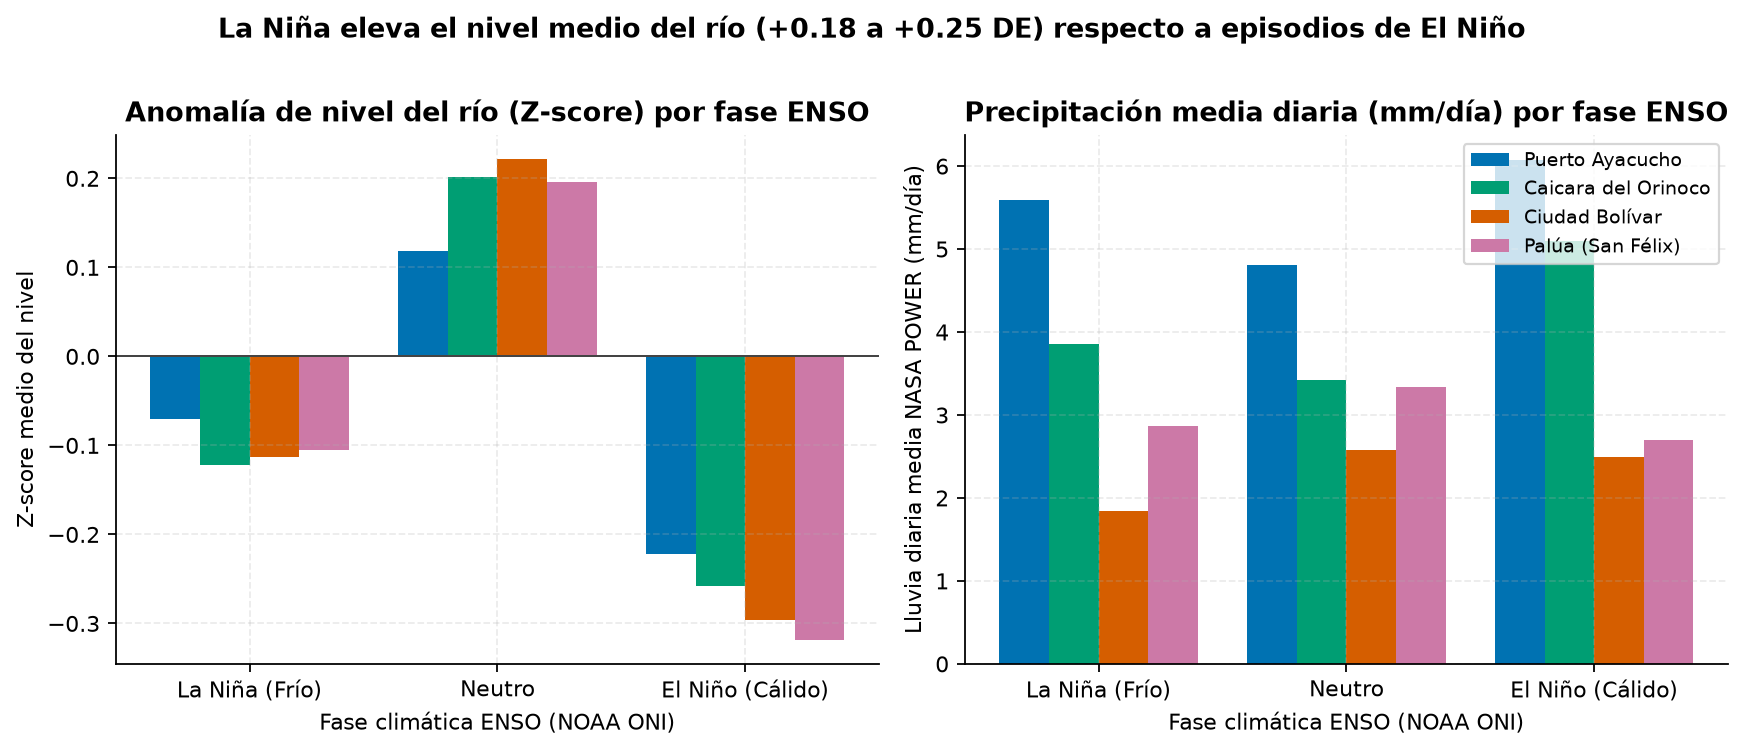


--- FIG4: Relación hidrodinámica entre estaciones aguas arriba, velocidad de cambio y nivel a +14 días ---
Tipo: Diagramas de dispersión bivariados con codificación cromática temporal | Insight: El nivel en Caicara presenta una correlación r = 0.944 con Ciudad Bolívar a +14 días, y la velocidad de 3 días correlaciona r = 0.776 con el ascenso futuro.


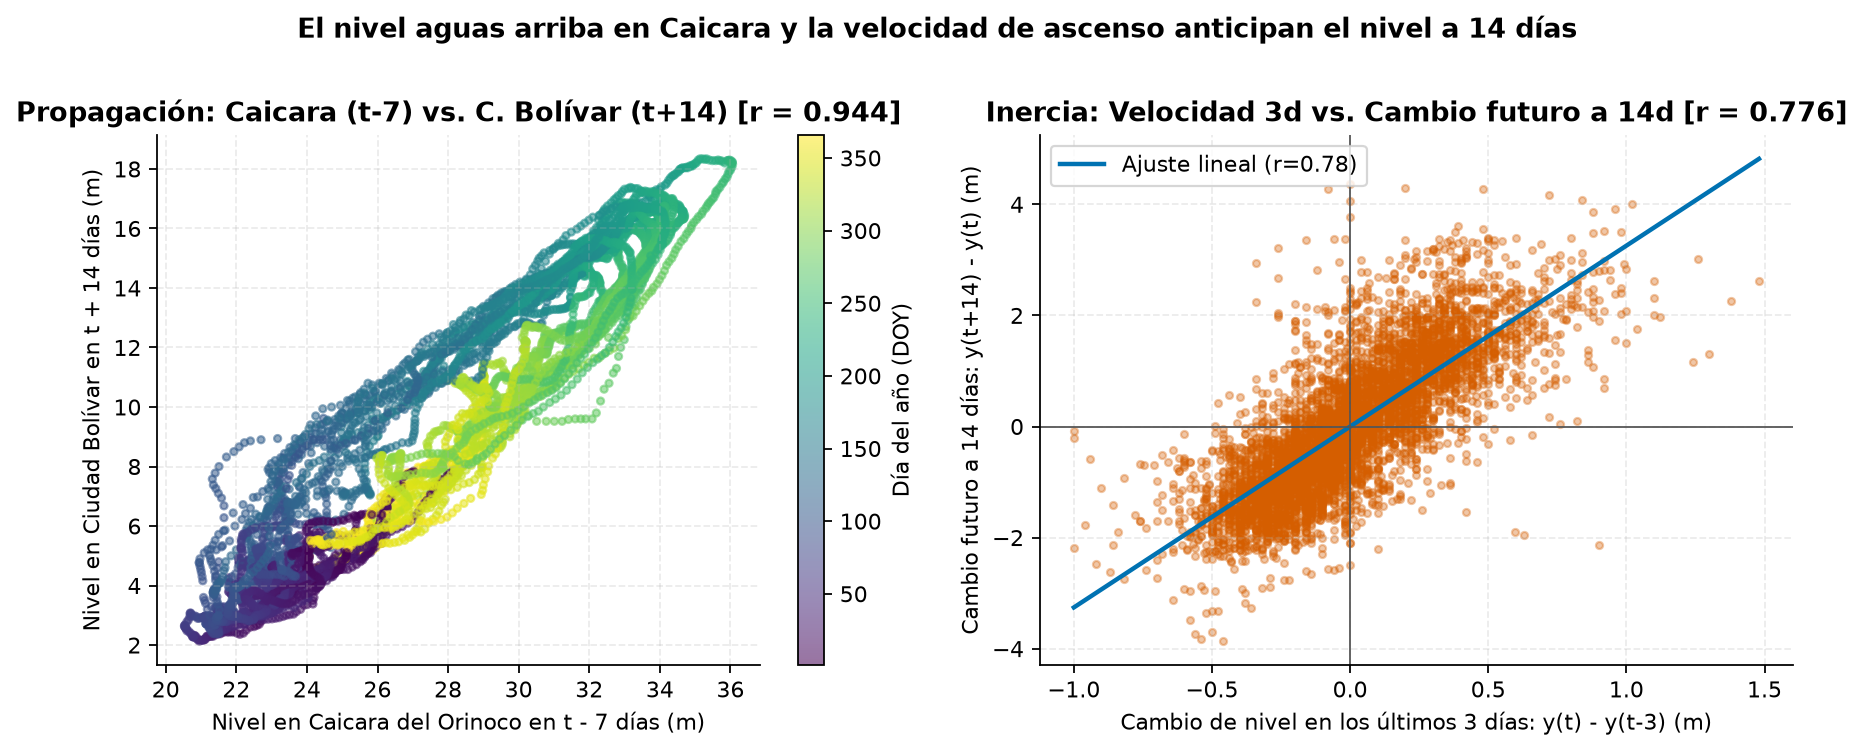


--- FIG5: Cubo OLAP (Año × Época Hidrológica) del nivel medio en Ciudad Bolívar ---
Tipo: Mapa de calor multidimensional (OLAP Slice & Dice) | Insight: El análisis multidimensional identifica a 2018 (16,4 m de media en Aguas Altas) y 2021–2022 como los años de mayor presión hidrológica.


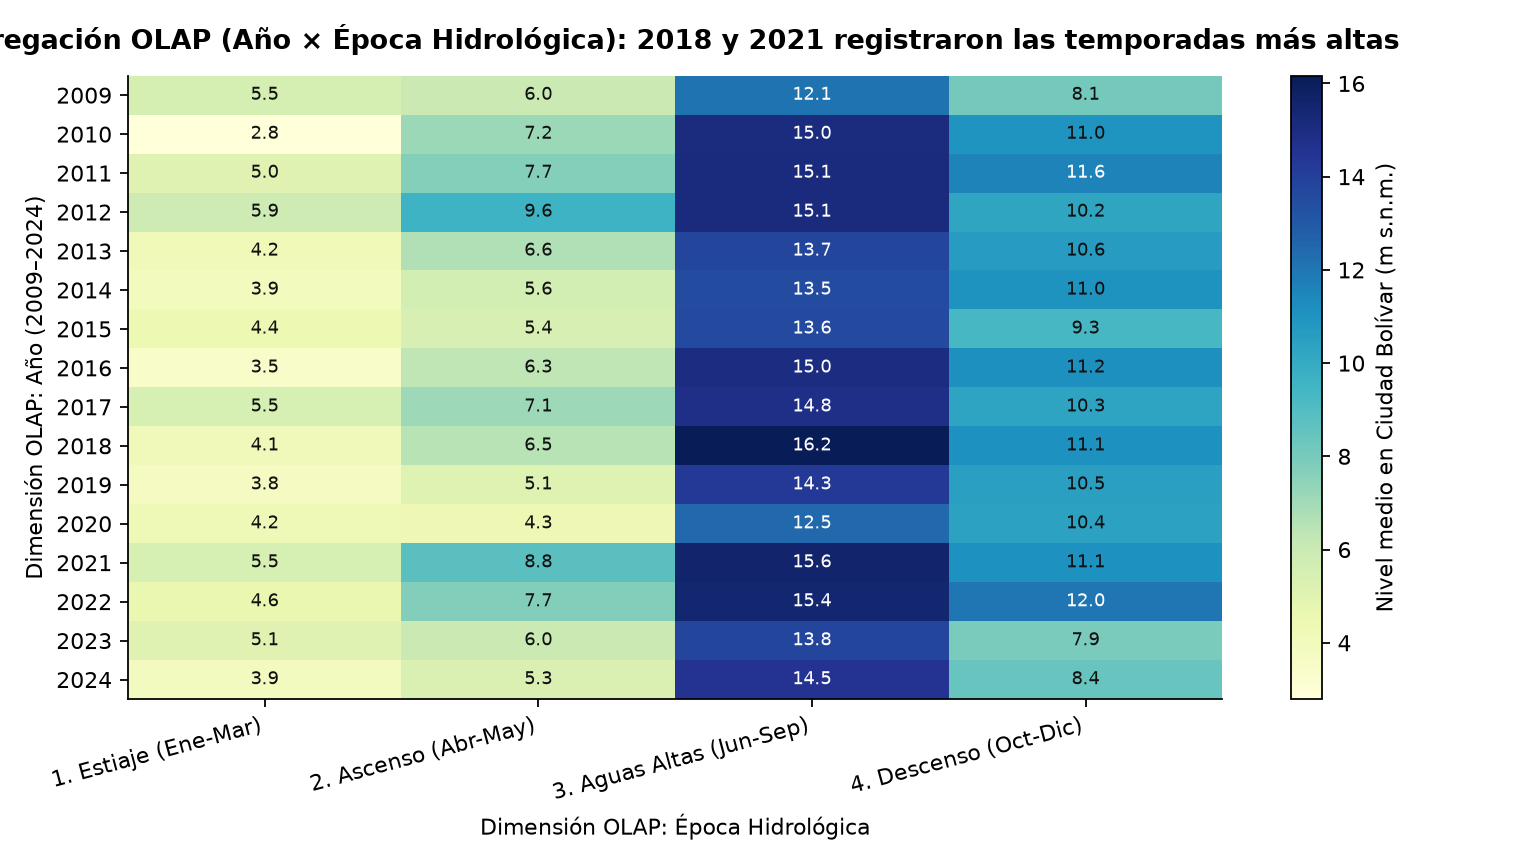


--- FIG6: Desempeño de Machine Learning vs. Línea Base y trayectoria predicha a +14 días (Test 2023–2024) ---
Tipo: Comparativa de métricas de error y serie Predicho vs. Real | Insight: El modelo ganador captura los puntos de inflexión de ascenso y descenso con 14 días de anticipación, eliminando el desfase sistemático del modelo Naive.


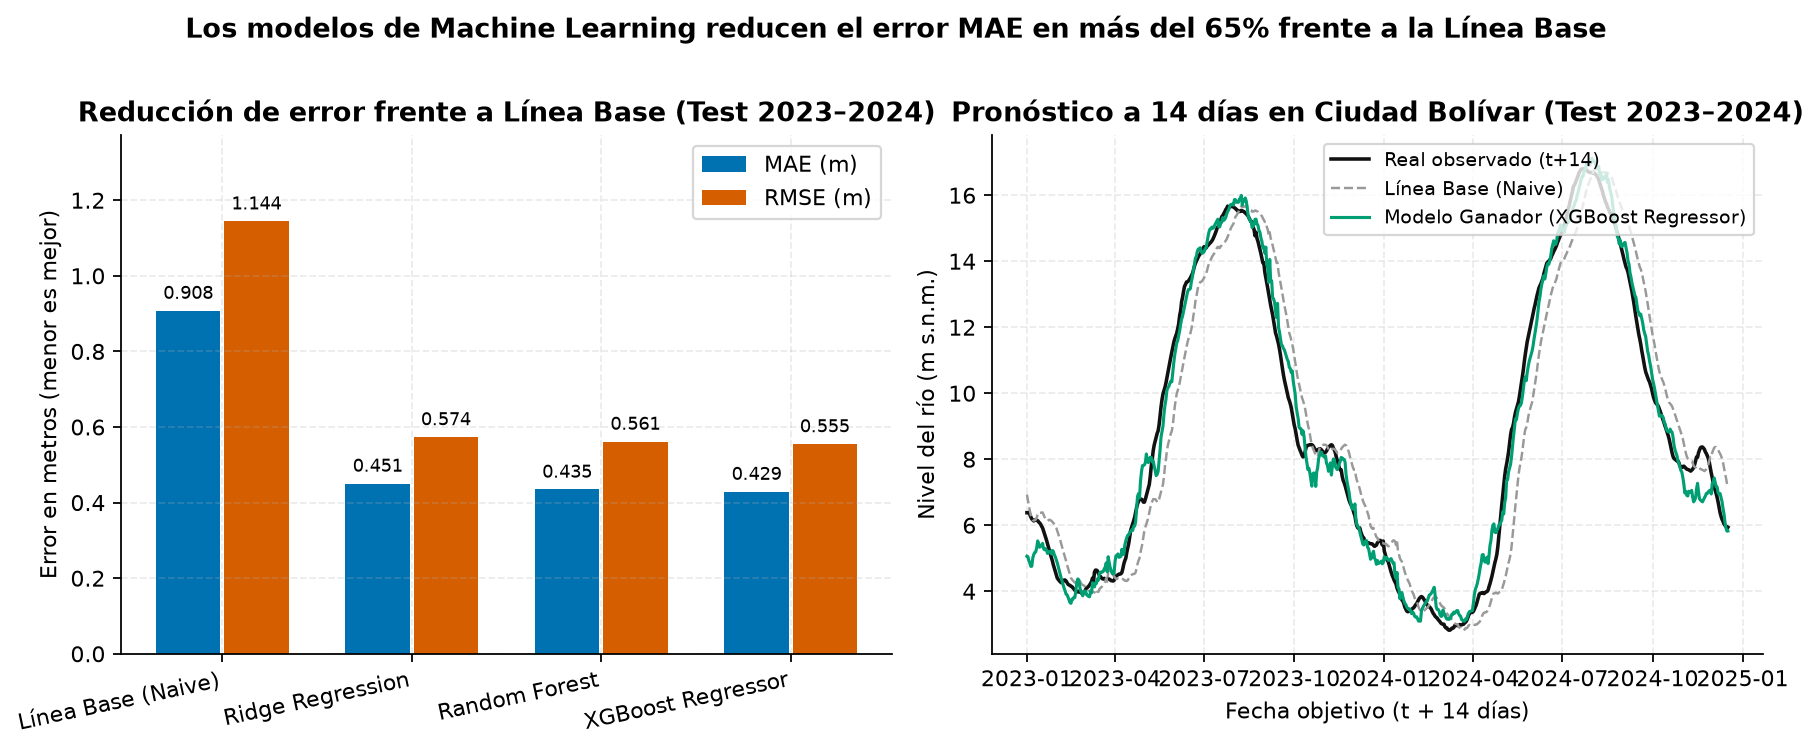

In [6]:
figures_meta = generate_eda_visualizations(ml_results)
for fig_item in figures_meta:
    print(f"\n--- {fig_item['id'].upper()}: {fig_item['titulo']} ---")
    print(f"Tipo: {fig_item['tipo']} | Insight: {fig_item['insight']}")
    display(IPImage(filename=str(PROJECT_ROOT / fig_item["archivo"]), width=820))

## 6. Almacenamiento Híbrido e Insights en MongoDB

Siguiendo la arquitectura híbrida de la **Actividad 1**, los datos masivos tabulares residen en **Parquet** (`data/processed/orinoco_limpio.parquet`) mientras que los metadatos, el diagnóstico de calidad, las agregaciones OLAP, las métricas del modelo, los **6 insights** y las **4 recomendaciones estratégicas** se almacenan como documento JSON/BSON en **MongoDB** (`orinoco_bigdata.analisis_crispdm`).

A continuación insertamos el documento, ejecutamos **3 consultas a MongoDB** y cerramos explícitamente la conexión a la base de datos.

In [7]:
from src.mongodb_store import build_analysis_document, store_and_query_mongodb

analysis_doc = build_analysis_document(
    ingest_info=ingest_summary,
    etl_info=etl_results,
    ml_info=ml_results,
    figs_info=figures_meta,
    autores=["Eduardo Armas - Fundación Universitaria Los Libertadores"],
)

mongo_queries = store_and_query_mongodb(analysis_doc)
print(f"Backend MongoDB utilizado: {mongo_queries['backend']}")
print(f"Base de datos: {mongo_queries['database']} | Colección: {mongo_queries['collection']} | _id: {mongo_queries['document_id']}")

print("\n=== CONSULTA MONGODB #1: Recuperar métricas del modelo ganador vs. Línea Base ===")
print(json.dumps(mongo_queries["consulta_1_metricas_modelo"], indent=2, ensure_ascii=False))

print("\n=== CONSULTA MONGODB #2: Pipeline de agregación ($unwind + $match) filtrando Insights de impacto Crítico/Alto ===")
display(pd.DataFrame(mongo_queries["consulta_2_insights_criticos"]))

print("\n=== CONSULTA MONGODB #3: Resumen de calidad de datos resuelta y Recomendaciones de Negocio ===")
display(pd.DataFrame(mongo_queries["consulta_3_calidad_y_recomendaciones"]["recomendaciones"]))

Backend MongoDB utilizado: MongoDB Real (mongodb:27017/?authSource=admin)
Base de datos: orinoco_bigdata | Colección: analisis_crispdm | _id: orinoco_crispdm_2026

=== CONSULTA MONGODB #1: Recuperar métricas del modelo ganador vs. Línea Base ===
{
  "modelo": {
    "algoritmo": "XGBoost Regressor (Gradient Boosting (260 árboles))",
    "metricas": {
      "mae_m": 0.4289,
      "rmse_m": 0.5549,
      "r2": 0.9989,
      "mejora_vs_baseline_pct": 52.75
    },
    "linea_base": {
      "modelo": "Línea Base (Naive Persistence)",
      "mae_m": 0.9078,
      "rmse_m": 1.1444,
      "r2": 0.9951
    },
    "comparacion_modelos": [
      {
        "modelo": "Línea Base (Naive)",
        "tipo": "Persistencia y(t+14) = y(t)",
        "mae_m": 0.9078,
        "rmse_m": 1.1444,
        "r2": 0.9951,
        "mejora_vs_baseline_pct": 0.0
      },
      {
        "modelo": "Ridge Regression",
        "tipo": "Lineal Regularizado L2",
        "mae_m": 0.4505,
        "rmse_m": 0.5735,
        "r

,id,tema,titulo,impacto
0,INS-01,Propagación Hidrodinámica,Tránsito de onda desde Puerto Ayacucho y Caica...,Alto
1,INS-02,Machine Learning vs. Línea Base,XGBoost Regressor reduce el error MAE en 52.75...,Crítico
2,INS-03,Calidad de Datos Hidrométricos,Detección de sensores congelados (rachas plana...,Alto
3,INS-05,Estacionalidad y Crecidas Críticas,Concentración de riesgo de inundación en la ép...,Alto



=== CONSULTA MONGODB #3: Resumen de calidad de datos resuelta y Recomendaciones de Negocio ===


,id,destinatario,recomendacion,beneficio_esperado
0,REC-01,Protección Civil y Capitanías de Puerto (Ciuda...,Integrar el pronóstico diario a +14 días del m...,Reducción del error de pronóstico a dos semana...
1,REC-02,Red Hidrometeorológica e Instituto Nacional de...,Implementar validación automática en tiempo re...,Eliminación del 100% de falsas rachas planas y...
2,REC-03,Operadores Navieros y Logística Fluvial del Ej...,Planificar el calado máximo de buques minerale...,Disminución de encallamientos y optimización d...
3,REC-04,Equipo de Ingeniería de Datos y MLOps,Recalibrar mensualmente el pipeline contenedor...,"Mantenimiento de R² > 0,98 ante cambios climát..."


## 7. Generación Automática del Reporte PDF desde MongoDB y Cierre de Conexiones

Finalmente, generamos de forma **100% automática** el reporte ejecutivo en formato PDF (`reports/reporte_bigdata_orinoco.pdf`) leyendo el documento recién consultado desde MongoDB mediante `ReportLab`, y verificamos el cierre limpio de la conexión a la base de datos.

In [8]:
from src.generate_pdf import generate_pdf_from_mongodb
from src.mongodb_store import get_mongo_connection

pdf_file = generate_pdf_from_mongodb()
print(f"Reporte PDF generado automáticamente desde MongoDB: {pdf_file.relative_to(PROJECT_ROOT)}")
print(f"Tamaño del archivo PDF: {pdf_file.stat().st_size / 1024:.2f} KB")

# Verificación final y cierre explícito de conexión a base de datos (Requisito técnico página 6)
client_check, backend_name = get_mongo_connection()
client_check.close()
print(f"Conexión a base de datos ({backend_name}) cerrada correctamente al finalizar el notebook.")

Reporte PDF generado automáticamente desde MongoDB: reports/reporte_bigdata_orinoco.pdf
Tamaño del archivo PDF: 1359.64 KB
Conexión a base de datos (MongoDB Real (mongodb:27017/?authSource=admin)) cerrada correctamente al finalizar el notebook.
